In [10]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [11]:
import os
import sys
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import FuncFormatter, MultipleLocator
import numpy as np
from tqdm import tqdm

from pathlib import Path
sys.path.append(str(Path.cwd().parents[0] / "src"))
from Moire_2bands import Moire
import utils

In [72]:
sys = Moire(theta_deg=2.0, psi_deg=58.0, V=10.0, n_shells=8)

In [73]:
plt.rcParams.update({
    'figure.figsize': (6, 5),
    'figure.dpi': 120,          # crisper on screen
    'savefig.dpi': 300,         # high-res when saving
    'font.size': 12,
    'axes.titlesize': 14,
    'axes.spines.top': True,   # remove top/right borders
    'axes.spines.right': True,
    'axes.grid': False,
    'lines.linewidth': 2,
    'xtick.labelsize': 16,
    'ytick.labelsize': 16,
})

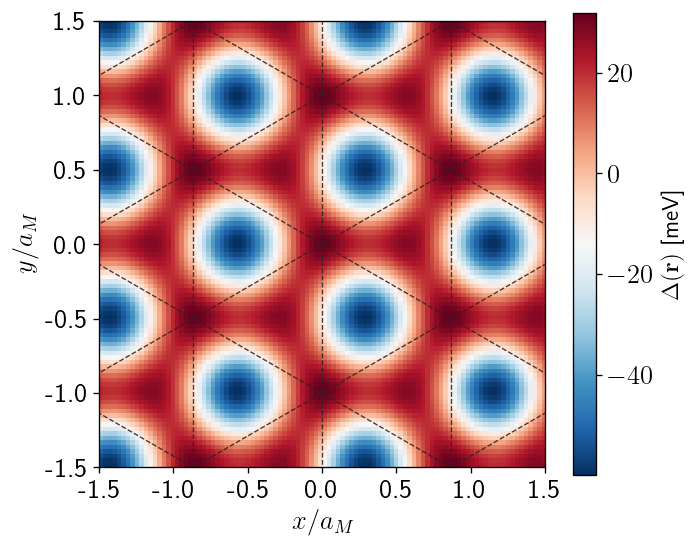

In [74]:
fig, ax = plt.subplots()
scale = 1.5
extent = [-scale * sys.aM, scale * sys.aM, -scale * sys.aM, scale * sys.aM]
im = sys.plot_moire_potential(ax, extent, resolution=100)
sys.plot_triangular_lattice(ax, extent)
cbar = fig.colorbar(im, ax=ax)
cbar.set_label(r"$\Delta(\mathbf{r})$ [meV]", fontsize=14)

aM_i = sys.aM
ax.xaxis.set_major_formatter(FuncFormatter(lambda val, pos, L=aM_i: f'{val/L:.1f}'))
ax.yaxis.set_major_formatter(FuncFormatter(lambda val, pos, L=aM_i: f'{val/L:.1f}'))
ax.xaxis.set_major_locator(MultipleLocator(0.5 * aM_i))
ax.yaxis.set_major_locator(MultipleLocator(0.5 * aM_i))
#sys.plot_triangular_lattice(ax, extent)

ax.set_xlabel(r'$x/a_M$', fontsize=16)
ax.set_ylabel(r'$y/a_M$', fontsize=16)
plt.savefig("plots/moire_potential.pdf", dpi=300, bbox_inches='tight')

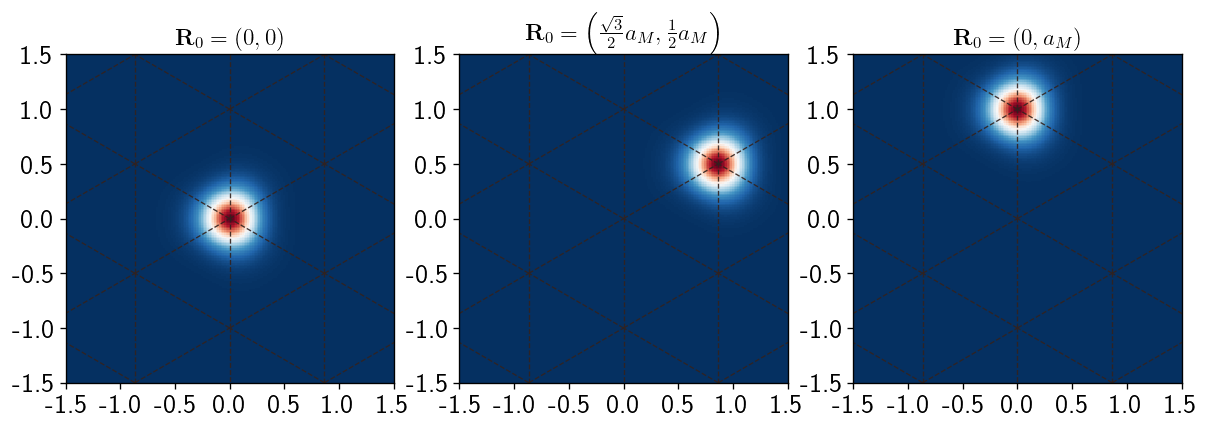

In [21]:
scale = 1.5
extent = [-scale * sys.aM, scale * sys.aM, -scale * sys.aM, scale * sys.aM]

Nx = 200
Ny = 200

x = np.linspace(-scale * sys.aM, scale * sys.aM, Nx)
y = np.linspace(-scale * sys.aM, scale * sys.aM, Ny)
X, Y = np.meshgrid(x, y)

k_points = sys.mesh_k_unit_cell(Nx=20, Ny=20)


fig, ax = plt.subplots(1, 3, figsize=(12, 8))
im = sys.plot_wannier_function(ax[0], X, Y, k_points)
sys.plot_triangular_lattice(ax[0], extent)
aM_i = sys.aM
ax[0].set_title(r"$\mathbf{R}_0 = \left(0, 0\right)$")
ax[0].xaxis.set_major_formatter(FuncFormatter(lambda val, pos, L=aM_i: f'{val/L:.1f}'))
ax[0].yaxis.set_major_formatter(FuncFormatter(lambda val, pos, L=aM_i: f'{val/L:.1f}'))
ax[0].xaxis.set_major_locator(MultipleLocator(0.5 * aM_i))
ax[0].yaxis.set_major_locator(MultipleLocator(0.5 * aM_i))

im = sys.plot_wannier_function(ax[1], X, Y, k_points, R0=np.array([np.sqrt(3) * sys.aM / 2, sys.aM / 2]))
sys.plot_triangular_lattice(ax[1], extent)
ax[1].set_title(r"$\mathbf{R}_0 = \left(\frac{\sqrt{3}}{2}a_M, \frac{1}{2}a_M\right)$")
ax[1].xaxis.set_major_formatter(FuncFormatter(lambda val, pos, L=aM_i: f'{val/L:.1f}'))
ax[1].yaxis.set_major_formatter(FuncFormatter(lambda val, pos, L=aM_i: f'{val/L:.1f}'))
ax[1].xaxis.set_major_locator(MultipleLocator(0.5 * aM_i))
ax[1].yaxis.set_major_locator(MultipleLocator(0.5 * aM_i))

im = sys.plot_wannier_function(ax[2], X, Y, k_points, R0=np.array([0.0, sys.aM]))
sys.plot_triangular_lattice(ax[2], extent)
ax[2].set_title(r"$\mathbf{R}_0 = \left(0, a_M\right)$")
ax[2].xaxis.set_major_formatter(FuncFormatter(lambda val, pos, L=aM_i: f'{val/L:.1f}'))
ax[2].yaxis.set_major_formatter(FuncFormatter(lambda val, pos, L=aM_i: f'{val/L:.1f}'))
ax[2].xaxis.set_major_locator(MultipleLocator(0.5 * aM_i))
ax[2].yaxis.set_major_locator(MultipleLocator(0.5 * aM_i))

### Disjoint Wannierization

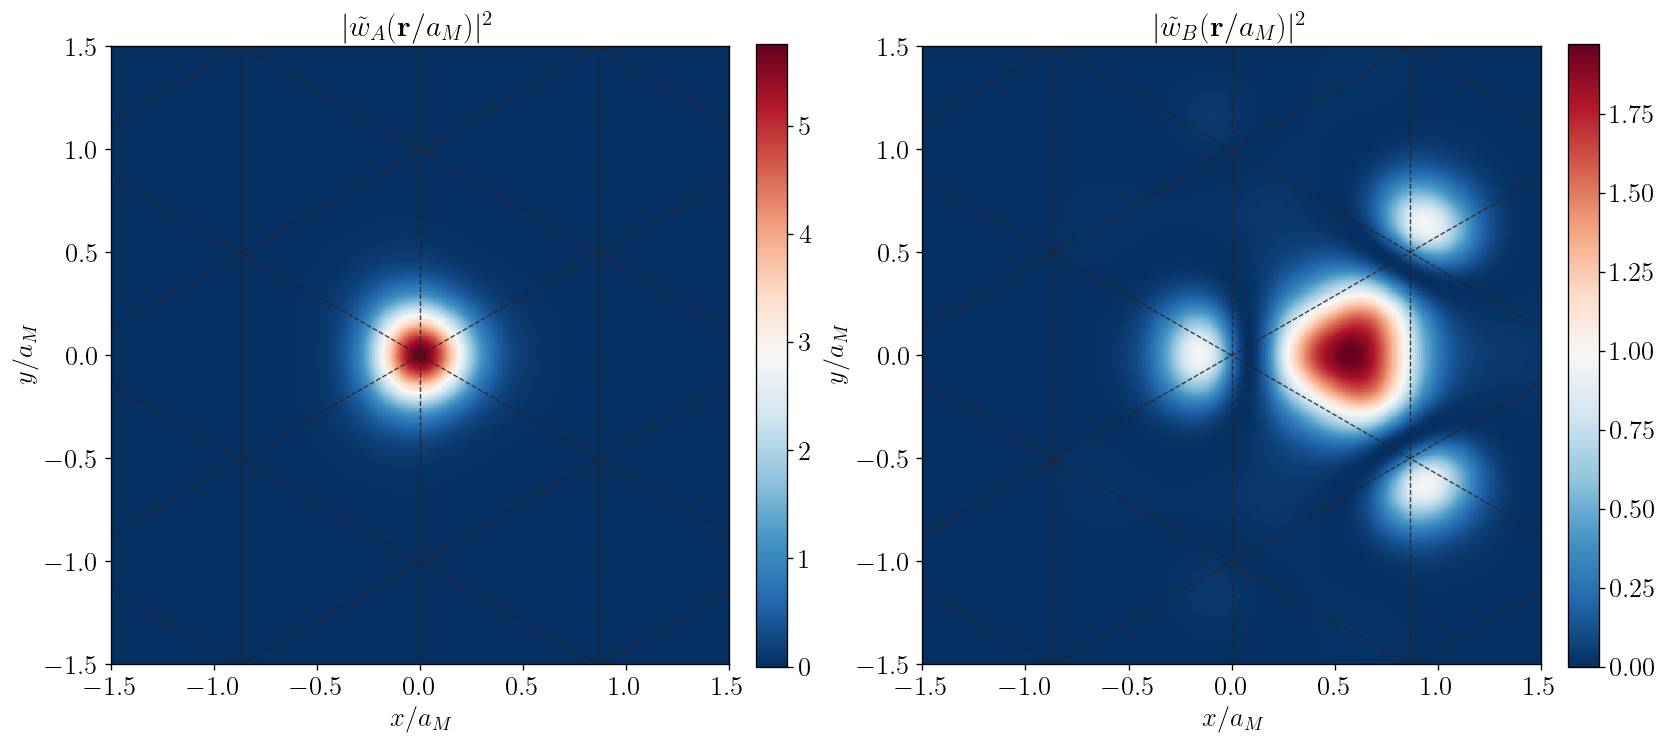

In [22]:
scale = 1.5
extent = [-scale * sys.aM, scale * sys.aM, -scale * sys.aM, scale * sys.aM]

Nx = 300
Ny = 300

x = np.linspace(-scale * sys.aM, scale * sys.aM, Nx)
y = np.linspace(-scale * sys.aM, scale * sys.aM, Ny)
X, Y = np.meshgrid(x, y)

k_points = sys.mesh_k_unit_cell(Nx=21, Ny=21)

## Trial functions centers
RA = np.zeros(2)
v2 = sys.a1.copy()
v2[1] = - v2[1]
RB = (sys.a1 + v2) / 3

wannier1 = sys.wannier_wavefunction_target_band(X, Y, k_points, target_band=1, gauge_fixed=True, R0=RA)
wannier2 = sys.wannier_wavefunction_target_band(X, Y, k_points, target_band=2, gauge_fixed=True, R0=RB)


fig, ax = plt.subplots(1, 2, figsize=(16, 8))

ax[0].set_title(r"$|\tilde{w}_A(\mathbf{r}/a_M)|^2$", fontsize=18)
ax[0].set_xlabel(r'$x/a_M$', fontsize=16)
ax[0].set_ylabel(r'$y/a_M$', fontsize=16)

aM_i = sys.aM
ax[0].xaxis.set_major_formatter(FuncFormatter(lambda val, pos, L=aM_i: f'${val/L:.1f}$'))
ax[0].yaxis.set_major_formatter(FuncFormatter(lambda val, pos, L=aM_i: f'${val/L:.1f}$'))
ax[0].xaxis.set_major_locator(MultipleLocator(0.5 * aM_i))
ax[0].yaxis.set_major_locator(MultipleLocator(0.5 * aM_i))

extent = [X.min(), X.max(), Y.min(), Y.max()]
sys.plot_triangular_lattice(ax[0], extent)
im0 = sys.plot_wavefunction(ax[0], wannier1, extent, norm=None, cmap='RdBu_r')
plt.colorbar(im0,fraction=0.046, pad=0.04)

ax[1].set_title(r"$|\tilde{w}_B(\mathbf{r}/a_M)|^2$", fontsize=18)
ax[1].set_xlabel(r'$x/a_M$', fontsize=16)
ax[1].set_ylabel(r'$y/a_M$', fontsize=16)
ax[1].xaxis.set_major_formatter(FuncFormatter(lambda val, pos, L=aM_i: f'${val/L:.1f}$'))
ax[1].yaxis.set_major_formatter(FuncFormatter(lambda val, pos, L=aM_i: f'${val/L:.1f}$'))
ax[1].xaxis.set_major_locator(MultipleLocator(0.5 * aM_i))
ax[1].yaxis.set_major_locator(MultipleLocator(0.5 * aM_i))
sys.plot_triangular_lattice(ax[1], extent)
im1 = sys.plot_wavefunction(ax[1], wannier2, extent, norm=None, cmap='RdBu_r')
plt.colorbar(im1, fraction=0.046, pad=0.04)
plt.savefig("plots/wanniers_disjoint.pdf", dpi=300, bbox_inches='tight')

### Joint Wannierization

[[0.40642751+0.j         0.0862326 +0.01102864j]
 [0.0862326 -0.01102864j 0.60732417+0.j        ]]


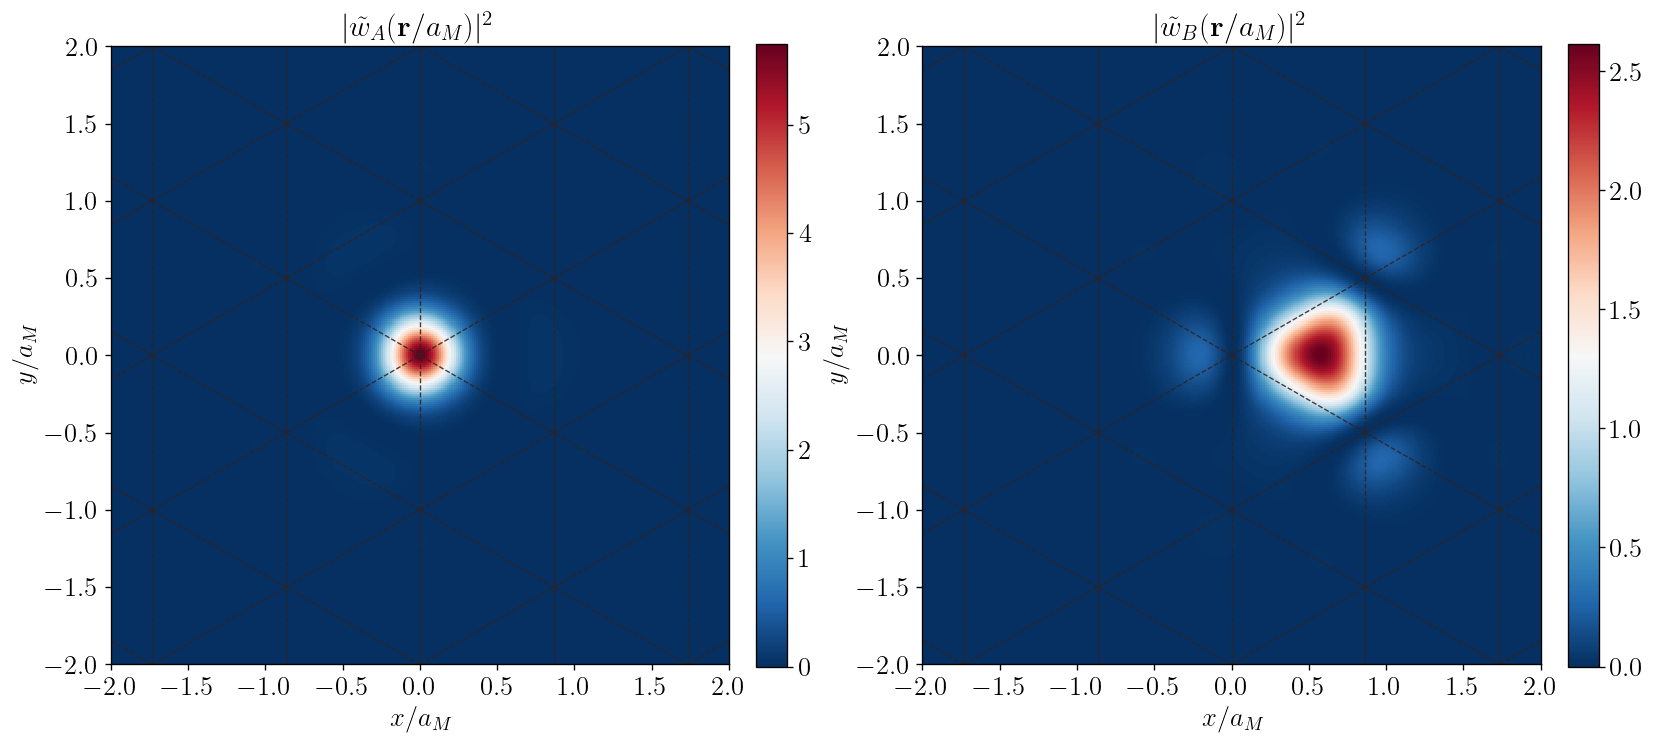

In [71]:
sys.theta_deg = 2.3
sys.psi_deg = 26
scale = 2.0
extent = [-scale * sys.aM, scale * sys.aM, -scale * sys.aM, scale * sys.aM]

Nx = 300
Ny = 300

x = np.linspace(-scale * sys.aM, scale * sys.aM, Nx)
y = np.linspace(-scale * sys.aM, scale * sys.aM, Ny)
X, Y = np.meshgrid(x, y)

k_points = sys.mesh_k_unit_cell(Nx=21, Ny=21)

## Trial functions centers
RA = np.zeros(2)
v2 = sys.a1.copy()
v2[1] = - v2[1]
RB = (sys.a1 + v2) / 3

wanniers = sys.wannier_wavefunction_2band(X, Y, k_points, trial_centers= np.array([RA, RB]))

wannier1 = wanniers[0, :, :]
wannier2 = wanniers[1, :, :]


fig, ax = plt.subplots(1, 2, figsize=(16, 8))

ax[0].set_title(r"$|\tilde{w}_A(\mathbf{r}/a_M)|^2$", fontsize=18)
ax[0].set_xlabel(r'$x/a_M$', fontsize=16)
ax[0].set_ylabel(r'$y/a_M$', fontsize=16)

aM_i = sys.aM
ax[0].xaxis.set_major_formatter(FuncFormatter(lambda val, pos, L=aM_i: f'${val/L:.1f}$'))
ax[0].yaxis.set_major_formatter(FuncFormatter(lambda val, pos, L=aM_i: f'${val/L:.1f}$'))
ax[0].xaxis.set_major_locator(MultipleLocator(0.5 * aM_i))
ax[0].yaxis.set_major_locator(MultipleLocator(0.5 * aM_i))

extent = [X.min(), X.max(), Y.min(), Y.max()]
sys.plot_triangular_lattice(ax[0], extent)
im0 = sys.plot_wavefunction(ax[0], wannier1, extent, norm=None, cmap='RdBu_r')
plt.colorbar(im0,fraction=0.046, pad=0.04)

ax[1].set_title(r"$|\tilde{w}_B(\mathbf{r}/a_M)|^2$", fontsize=18)
ax[1].set_xlabel(r'$x/a_M$', fontsize=16)
ax[1].set_ylabel(r'$y/a_M$', fontsize=16)
ax[1].xaxis.set_major_formatter(FuncFormatter(lambda val, pos, L=aM_i: f'${val/L:.1f}$'))
ax[1].yaxis.set_major_formatter(FuncFormatter(lambda val, pos, L=aM_i: f'${val/L:.1f}$'))
ax[1].xaxis.set_major_locator(MultipleLocator(0.5 * aM_i))
ax[1].yaxis.set_major_locator(MultipleLocator(0.5 * aM_i))
sys.plot_triangular_lattice(ax[1], extent)
im1 = sys.plot_wavefunction(ax[1], wannier2, extent, norm=None, cmap='RdBu_r')
plt.colorbar(im1, fraction=0.046, pad=0.04)
plt.savefig("plots/wanniers_joint.pdf", dpi=300, bbox_inches='tight')

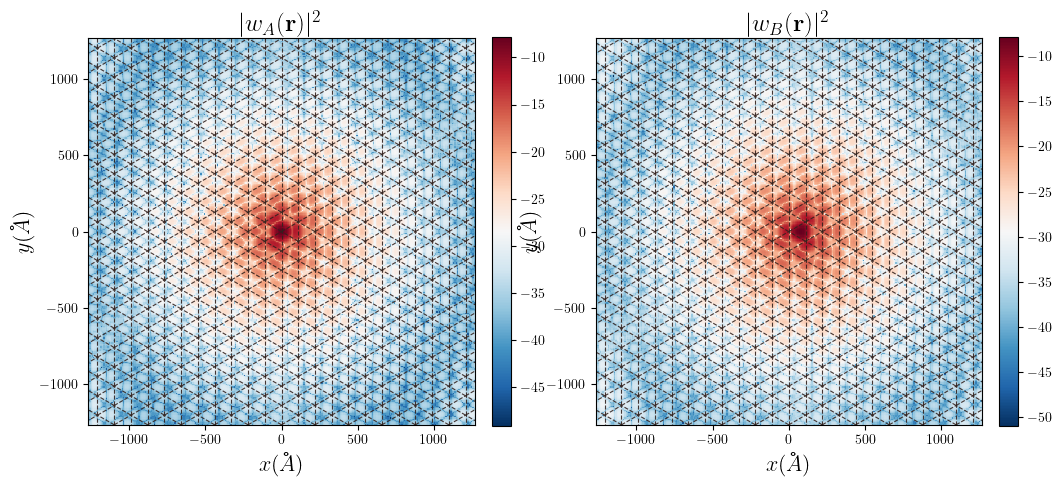

In [92]:
scale = 10.0
extent = [-scale * sys.aM, scale * sys.aM, -scale * sys.aM, scale * sys.aM]

Nx = 300
Ny = 300

x = np.linspace(-scale * sys.aM, scale * sys.aM, Nx)
y = np.linspace(-scale * sys.aM, scale * sys.aM, Ny)
X, Y = np.meshgrid(x, y)

k_points = sys.mesh_k_unit_cell(Nx=21, Ny=21)

## Trial functions centers
RA = np.zeros(2)
v2 = sys.a1.copy()
v2[1] = - v2[1]
RB = (sys.a1 + v2) / 3

wanniers = sys.wannier_wavefunction_2band(X, Y, k_points, trial_centers= np.array([RA, RB]))

wannier1 = wanniers[0, :, :]
wannier2 = wanniers[1, :, :]


fig, ax = plt.subplots(1, 2, figsize=(12, 8))
im = sys.plot_wannier_function(ax[0], X, Y, k_points)

ax[0].set_title(r"$|w_A(\mathbf{r})|^2$", fontsize=18)
ax[0].set_xlabel(r'$x (\AA)$', fontsize=16)
ax[0].set_ylabel(r'$y (\AA)$', fontsize=16)
extent = [X.min(), X.max(), Y.min(), Y.max()]
sys.plot_triangular_lattice(ax[0], extent)
im0 = ax[0].imshow(np.log(np.abs(wannier1)**2), extent=extent, origin='lower', 
                    interpolation='none', cmap='RdBu_r')
plt.colorbar(im0,fraction=0.046, pad=0.04)

ax[1].set_title(r"$|w_B(\mathbf{r})|^2$", fontsize=18)
ax[1].set_xlabel(r'$x (\AA)$', fontsize=16)
ax[1].set_ylabel(r'$y (\AA)$', fontsize=16)
sys.plot_triangular_lattice(ax[1], extent)
im1 = ax[1].imshow(np.log(np.abs(wannier2)**2), extent=extent, origin='lower', 
                    interpolation='none', cmap='RdBu_r')
plt.colorbar(im1, fraction=0.046, pad=0.04)

In [40]:
fun_one = lambda xx, yy: 1
print("Norm1: ", sys.integrate_wannier(fun_one, wannier1, X, Y, k_points))
print("Norm2: ", sys.integrate_wannier(fun_one, wannier2, X, Y, k_points))

Norm1:  0.9888693540219925
Norm2:  0.9130078605210319


4it [03:23, 50.84s/it]
4it [05:47, 86.98s/it] 
4it [03:35, 53.89s/it]


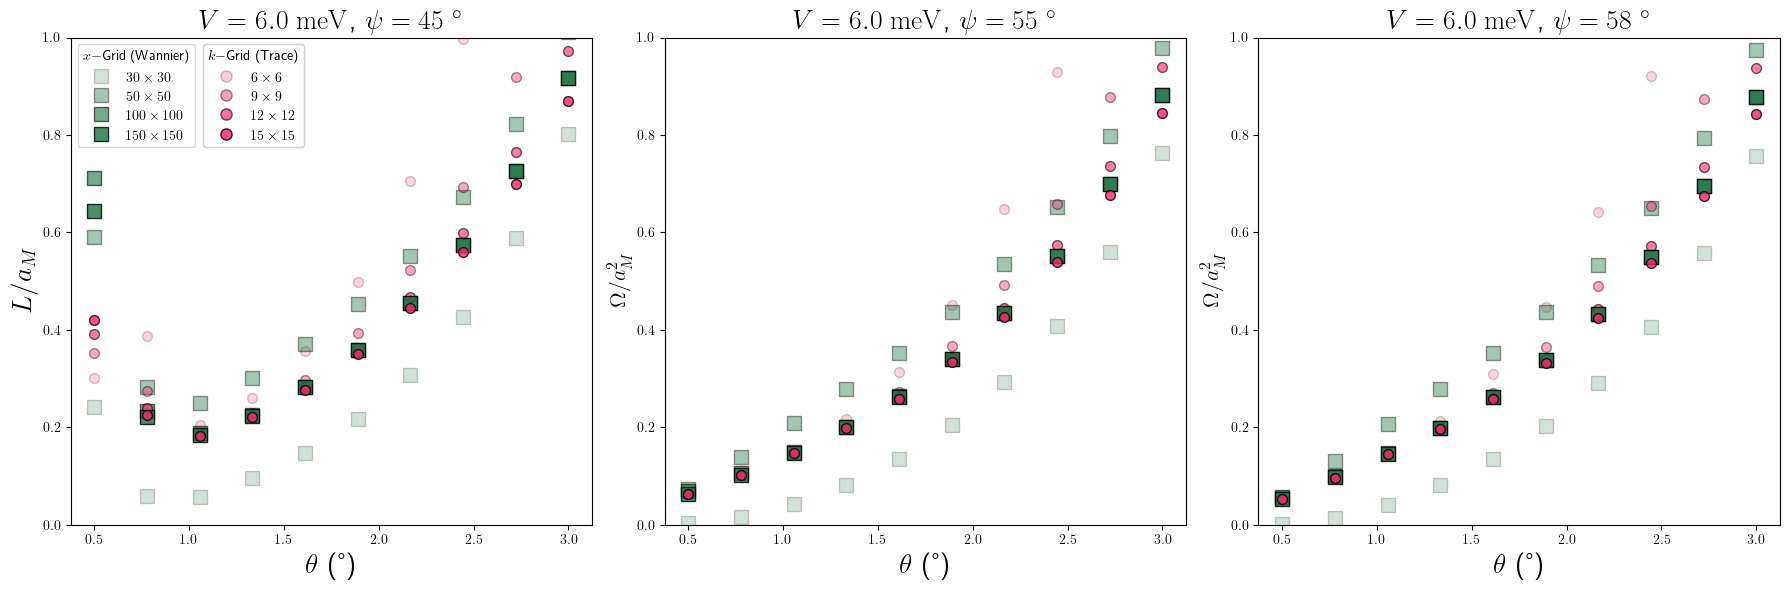

In [ ]:
sys.n_shells = 10
sys.V = 6.6
thetas = np.linspace(0.5, 3.0, 10)
thetas2 = np.linspace(thetas[0], thetas[-1], 100)
aMs0 = sys.a0 / (2 * np.sin(np.radians(thetas / 2)))
aMs = sys.a0 / (2 * np.sin(np.radians(thetas2 / 2)))

scale_W = 12.0

NxR = 100
NyR = 100

NxK = 21
NyK = NxK

k_res = [6, 9, 12, 15]
k_alpha = [0.2, 0.4, 0.6, 0.8]
x_res = [30, 50, 100, 150]
x_alpha = [0.2, 0.4, 0.6, 0.8]

psi_values = [45, 55, 58]

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for ax, psi in zip(axes, psi_values):
    sys.psi_deg = psi

    for resx, resk, alphax, alphak in tqdm(zip(x_res, k_res, x_alpha, k_alpha)):
        rW_values = []
        l0_values = []
        omega = []
        for th in thetas:
            sys.theta_deg = th

            x = np.linspace(-scale_W * sys.aM, scale_W * sys.aM, resx)
            y = np.linspace(-scale_W * sys.aM, scale_W * sys.aM, resx)
            X, Y = np.meshgrid(x, y)
            k_points = sys.mesh_k_unit_cell(Nx=NxK, Ny=NyK)

            ## Trial functions centers
            RA = np.zeros(2)
            v2 = sys.a1.copy()
            v2[1] = - v2[1]
            RB = (sys.a1 + v2) / 3

            wanniers = sys.wannier_wavefunction_2band(X, Y, k_points, trial_centers= np.array([RA, RB]))

            wannier1 = wanniers[0, :, :]
            wannier2 = wanniers[1, :, :]

            fun_one = lambda xx, yy: 1
            fun = lambda xx, yy: (xx-RA[0])**2 + (yy-RA[1])**2
            spread1 = sys.integrate_wannier(fun, wannier1, X, Y, k_points)

            fun2 = lambda xx, yy: (xx-RB[0])**2 + (yy-RB[1])**2
            spread2 = sys.integrate_wannier(fun2, wannier2, X, Y, k_points)
            
            omega.append((spread1 + spread2) / sys.aM**2)
            # print("Norm1: ", sys.integrate_wannier(fun_one, wannier1, X, Y, k_points))
            # print("Norm2: ", sys.integrate_wannier(fun_one, wannier2, X, Y, k_points))
            # print("Max abs wannier1: ", np.max(np.abs(wannier1)**2))
            # print("sp1: ", spread1 / sys.aM**2, "sp2: ", spread2 / sys.aM**2)
            # print("--------")

            # integral = sys.integrate_trace(Nx=resk, Ny=resk)
            # l0 = np.sqrt(integral)
            # l0_valuesH.append(l0)
            integral = sys.integrate_trace(Nx=resk, Ny=resk)
            l0_values.append(integral / sys.aM**2)

        ax.scatter(thetas, np.array(omega), facecolors='#197340', edgecolors='k',
                   s=100, marker='s', alpha=alphax)
        ax.scatter(thetas, np.array(l0_values), facecolors='#FF216B', edgecolors='k',
                   s=50, alpha=alphak)
        ax.set_ylim([0, 1])
        ax.set_xlabel(r'$\theta$ [deg]', fontsize=16)
        ax.set_ylabel(r'$\Omega / a_M^2$', fontsize=16)
        ax.set_title(r'$\psi = {}^\circ$'.format(psi), fontsize=16)
    
    # --- Resolution legends (only on the first subplot to avoid clutter) ---
    if ax == axes[0]:
        legend_x_handles = [
            Line2D([0], [0], marker='s', color='w', label=rf'${resx} \times {resx}$',
                   markerfacecolor='#197340', markeredgecolor='k',
                   markersize=10, alpha=alphax)
            for resx, alphax in zip(x_res, x_alpha)
        ]
        legend_k_handles = [
            Line2D([0], [0], marker='o', color='w', label=rf'${resk} \times {resk}$',
                   markerfacecolor='#FF216B', markeredgecolor='k',
                   markersize=8, alpha=alphak)
            for resk, alphak in zip(k_res, k_alpha)
        ]

        # leg_x = ax.legend(handles=legend_x_handles, title=r'$x-$Grid',
        #                   fontsize=10, title_fontsize=10, loc='upper left')
        # leg_k = ax.legend(handles=legend_k_handles, title=r'$k-$Grid',
        #                   fontsize=10, title_fontsize=10, loc='center right')
        # ax.add_artist(leg_x)
        leg_x = ax.legend(handles=legend_x_handles, title=r'$x-$Grid (Wannier)',
                  fontsize=10, title_fontsize=10,
                  loc='upper left', bbox_to_anchor=(0, 1))
        leg_k = ax.legend(handles=legend_k_handles, title=r'$k-$Grid (Trace)',
                        fontsize=10, title_fontsize=10,
                        loc='upper left', bbox_to_anchor=(0.24, 1))
        ax.add_artist(leg_x)
        plt.savefig("plots/spread_vs_theta.pdf", dpi=300, bbox_inches='tight')

    # --- Line legend on every subplot ---

    if ax == axes[0]:
        ax.add_artist(leg_k)

    ax.set_title(rf"$V = {sys.V}\ \mathrm{{meV}}$, $\psi = {sys.psi_deg}\ ^\circ$", fontsize=20)
    ax.set_xlabel(r'$\theta$ (°)', fontsize=20)
    ax.set_ylim([0.0, 1.0])

axes[0].set_ylabel(r'$L / a_M$', fontsize=20)

plt.tight_layout()
plt.savefig("plots/spread_vs_theta.pdf", dpi=300, bbox_inches='tight')
plt.show()

In [11]:
sys.n_shells = 12
sys.V = 10
thetas = np.linspace(0.4, 3.0, 23)
thetas2 = np.linspace(thetas[0], thetas[-1], 100)
aMs0 = sys.a0 / (2 * np.sin(np.radians(thetas / 2)))
aMs = sys.a0 / (2 * np.sin(np.radians(thetas2 / 2)))

scale_W = 12.0

NxR = 100
NyR = 100

NxK = 21
NyK = NxK

k_res = 15
resk = 16
k_alpha = .8
x_res = 150
x_alpha = .8

resx = 150

sys.psi_deg = 58

rW_values = []
l0_values = []
omega = []
omega_disjoint = []
for th in tqdm(thetas):
    sys.theta_deg = th

    x = np.linspace(-scale_W * sys.aM, scale_W * sys.aM, resx)
    y = np.linspace(-scale_W * sys.aM, scale_W * sys.aM, resx)
    X, Y = np.meshgrid(x, y)
    k_points = sys.mesh_k_unit_cell(Nx=NxK, Ny=NyK)

    ## Trial functions centers
    RA = np.zeros(2)
    v2 = sys.a1.copy()
    v2[1] = - v2[1]
    RB = (sys.a1 + v2) / 3

    ### Joint wannierization

    wanniers = sys.wannier_wavefunction_2band(X, Y, k_points, trial_centers= np.array([RA, RB]))

    wannier1 = wanniers[0, :, :]
    wannier2 = wanniers[1, :, :]

    fun_one = lambda xx, yy: 1
    fun = lambda xx, yy: (xx-RA[0])**2 + (yy-RA[1])**2
    spread1 = sys.integrate_wannier(fun, wannier1, X, Y, k_points)

    fun2 = lambda xx, yy: (xx-RB[0])**2 + (yy-RB[1])**2
    spread2 = sys.integrate_wannier(fun2, wannier2, X, Y, k_points)
    
    omega.append((spread1 + spread2) / sys.aM**2)
    ###

    ### Disjoint wannierization
    wannierA = sys.wannier_wavefunction_target_band(X, Y, k_points, target_band=1, gauge_fixed=True, R0=RA)
    wannierB = sys.wannier_wavefunction_target_band(X, Y, k_points, target_band=2, gauge_fixed=True, R0=RB)
    
    fun = lambda xx, yy: (xx-RA[0])**2 + (yy-RA[1])**2
    spreadA = sys.integrate_wannier(fun, wannierA, X, Y, k_points)

    fun = lambda xx, yy: (xx-RB[0])**2 + (yy-RB[1])**2
    spreadB = sys.integrate_wannier(fun, wannierB, X, Y, k_points)

    omega_disjoint.append((spreadA + spreadB) / sys.aM**2)
    ###

    ### Trace integral
    integral = sys.integrate_trace(Nx=resk, Ny=resk)
    l0_values.append(integral / sys.aM**2)

  0%|          | 0/23 [00:00<?, ?it/s]

100%|██████████| 23/23 [09:36<00:00, 25.07s/it]


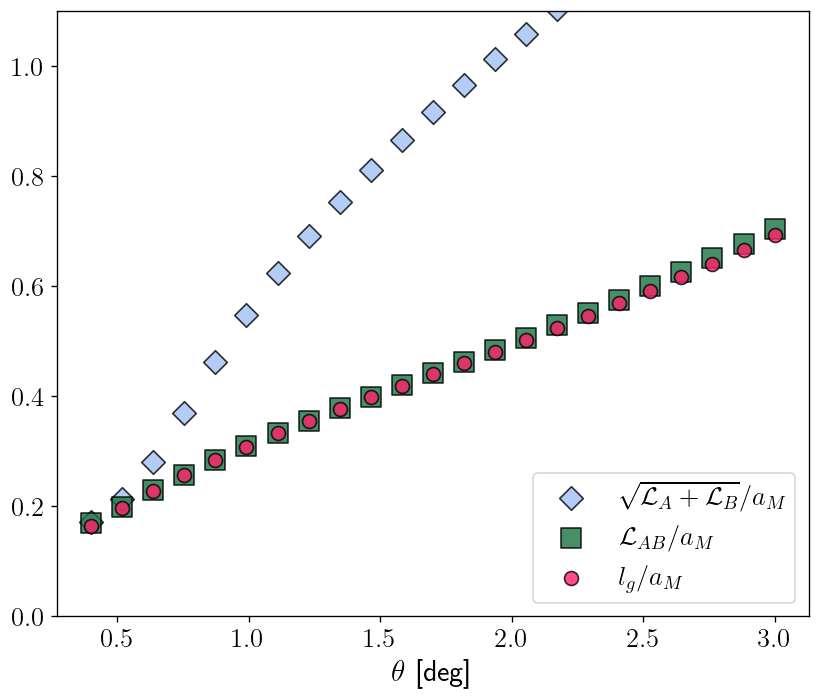

In [ ]:
alphax = .8
alphak = .8
fig, ax = plt.subplots(1, 1, figsize=(7, 6))

ax.scatter(thetas, np.sqrt(omega_disjoint), facecolors='#A1C1F4', edgecolors='k',
            s=100, marker='D', alpha=alphax, label=r'$\sqrt{\mathcal{L}_A + \mathcal{L}_B} / a_M$')
ax.plot(thetas, np.sqrt(omega), facecolors='#197340', edgecolors='k',
            s=150, marker='s', alpha=alphax, label=r'$\mathcal{L}_{AB} / a_M$')
ax.scatter(thetas, np.sqrt(l0_values), facecolors='#FF216B', edgecolors='k',
            s=70, alpha=alphak, label=r'$l_g / a_M$')
ax.set_ylim([0, 1.1])
ax.set_xlabel(r"$\theta$ [deg]", fontsize=18)
ax.legend(fontsize=16, loc='lower right')

#ax.set_ylim([0.0, 1.0])

plt.tight_layout()
plt.savefig("plots/wannierization_comparison.pdf", dpi=300, bbox_inches='tight')
plt.show()

### Quantum Metric

In [109]:
scale = 1.2
kx = np.linspace(-scale * sys.kappa_pp[0], scale * sys.kappa_pp[0], 50)
ky = np.linspace(-scale * sys.kappa_p[1], scale * sys.kappa_p[1], 50)
KX, KY = np.meshgrid(kx, ky)
k_points = np.column_stack([KX.ravel(), KY.ravel()])
g_xx, g_xy, g_yy = sys.quantum_metric(k_points)

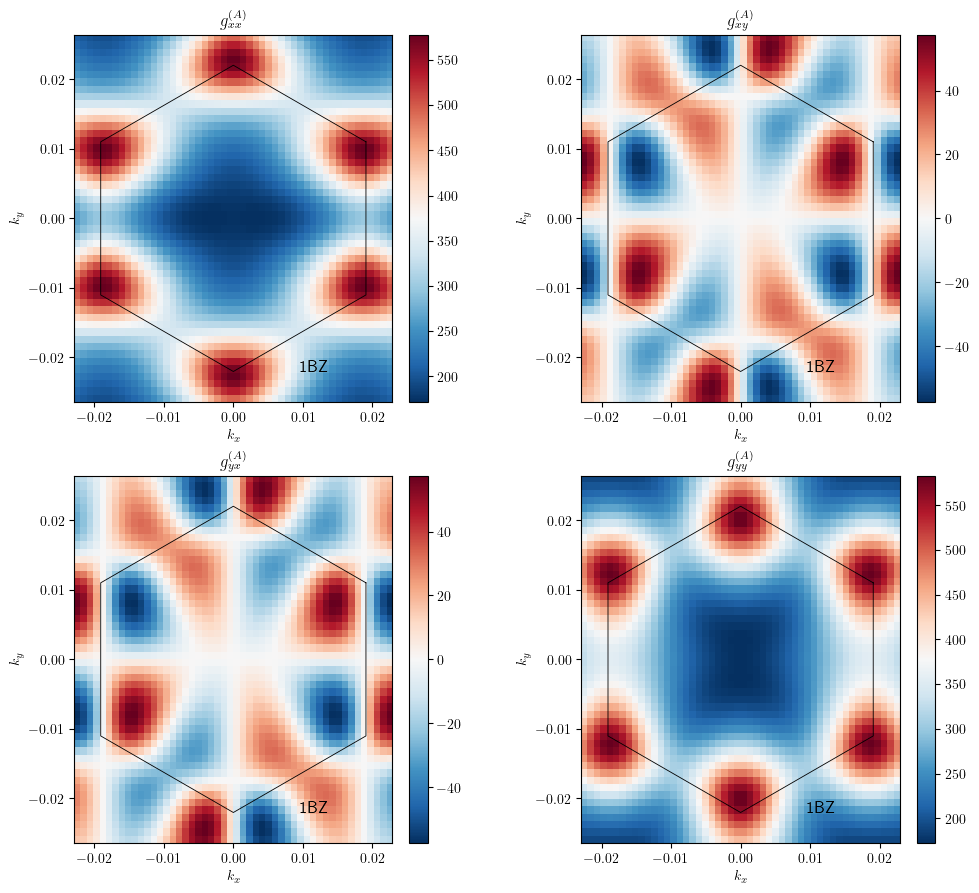

In [110]:
fig, ax = plt.subplots(2, 2, figsize=(12, 10.5))
scale = 1.2
kx = np.linspace(-scale * sys.kappa_pp[0], scale * sys.kappa_pp[0], 50)
ky = np.linspace(-scale * sys.kappa_p[1], scale * sys.kappa_p[1], 50)
KX, KY = np.meshgrid(kx, ky)
sys.plot_metric_band(ax, KX, KY, band=0, mask_bz=False)

plt.xlabel(r'$k_x$')
plt.ylabel(r'$k_y$')
plt.savefig("plots/quantum_metric_band_A.pdf", dpi=300, bbox_inches='tight')

In [ ]:
fig, ax = plt.subplots(figsize=(8, 6))
scale = 1.2
kx = np.linspace(-scale * sys.kappa_pp[0], scale * sys.kappa_pp[0], 50)
ky = np.linspace(-scale * sys.kappa_p[1], scale * sys.kappa_p[1], 50)
KX, KY = np.meshgrid(kx, ky)
sys.plot_trace_metric_band(ax, KX, KY, band=0, mask_bz=False)

plt.xlabel(r'$k_x$')
plt.ylabel(r'$k_y$')
plt.savefig("plots/trace_quantum_metric_band_A.pdf", dpi=300, bbox_inches='tight')

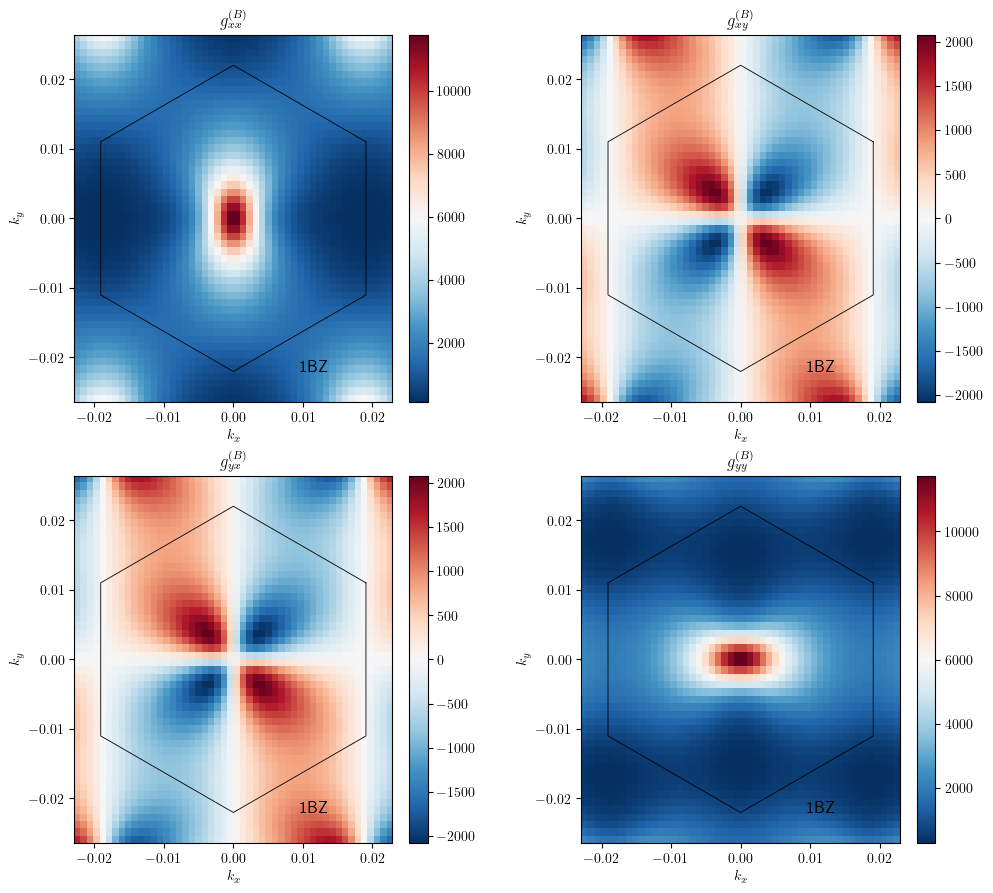

In [112]:
fig, ax = plt.subplots(2, 2, figsize=(12, 10.5))
scale = 1.2
kx = np.linspace(-scale * sys.kappa_pp[0], scale * sys.kappa_pp[0], 50)
ky = np.linspace(-scale * sys.kappa_p[1], scale * sys.kappa_p[1], 50)
KX, KY = np.meshgrid(kx, ky)
sys.plot_metric_band(ax, KX, KY, band=1, mask_bz=False)

plt.xlabel(r'$k_x$')
plt.ylabel(r'$k_y$')
plt.savefig("plots/quantum_metric_band_B.pdf", dpi=300, bbox_inches='tight')

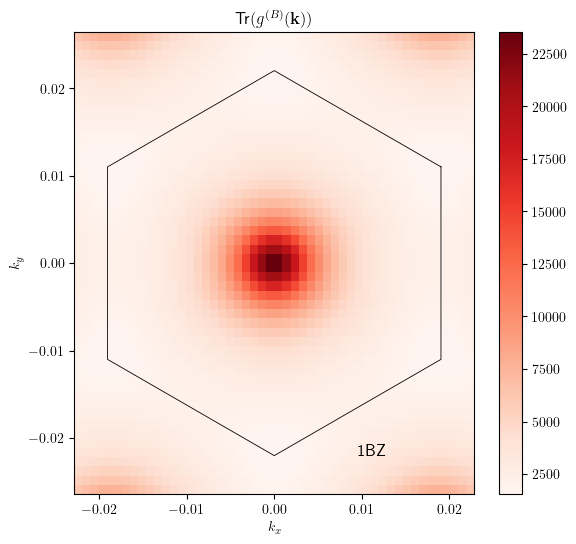

In [113]:
fig, ax = plt.subplots(figsize=(8, 6))
scale = 1.2
kx = np.linspace(-scale * sys.kappa_pp[0], scale * sys.kappa_pp[0], 50)
ky = np.linspace(-scale * sys.kappa_p[1], scale * sys.kappa_p[1], 50)
KX, KY = np.meshgrid(kx, ky)
sys.plot_trace_metric_band(ax, KX, KY, band=1, mask_bz=False)

plt.xlabel(r'$k_x$')
plt.ylabel(r'$k_y$')
plt.savefig("plots/trace_quantum_metric_band_B.pdf", dpi=300, bbox_inches='tight')